In [15]:
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import sys
sys.path.append(os.path.abspath(".."))   # one level up
import numpy as np
import cv2
import open3d as o3d
from scipy.spatial.transform import Rotation
from utils.lidar import PointCloud
from utils.camera import ImageData
import utils.utils as utils
from natsort import natsorted

from utils.utils import get_corr_files
import hazard_detection.map_based_utils as mb_utils

cmap = plt.get_cmap("jet")
LABEL_UNKNOWN = -1

def voxel_iou(gt, pred, cls, voxel_size=0.5, region_pts=None):
    """
    gt, pred   : (N, 5) arrays [x, y, z, i, class]
    cls        : class id to score
    voxel_size : cell size (same units as xyz)
    region_pts : optional (M, 3) points defining the evaluation region
                 (e.g. the missing-area points); only voxels containing
                 these are scored. If None, all voxels are used.
    Returns IoU for `cls` (nan if the class is absent from both).
    """
    gt, pred = np.asarray(gt), np.asarray(pred)
    origin = np.minimum(gt[:, :3].min(0), pred[:, :3].min(0))

    def to_idx(xyz):
        return np.floor((xyz - origin) / voxel_size).astype(np.int64)

    gi, pi = to_idx(gt[:, :3]), to_idx(pred[:, :3])
    ri = to_idx(np.asarray(region_pts)[:, :3]) if region_pts is not None else None

    all_idx = [gi, pi] + ([ri] if ri is not None else [])
    dims = np.max([a.max(0) for a in all_idx], axis=0) + 1

    def key(idx):
        return (idx[:, 0] * dims[1] + idx[:, 1]) * dims[2] + idx[:, 2]

    n_cls = int(max(gt[:, 4].max(), pred[:, 4].max())) + 1

    def majority_label(idx, labels):
        k = key(idx)
        pair, counts = np.unique(k * n_cls + labels.astype(np.int64),
                                 return_counts=True)
        vk, vc = pair // n_cls, pair % n_cls
        order = np.lexsort((-counts, vk))          # per voxel: highest count first
        vk, vc = vk[order], vc[order]
        first = np.unique(vk, return_index=True)[1]
        return vk[first], vc[first]                # voxel keys, majority class

    gk, gc = majority_label(gi, gt[:, 4])
    pk, pc = majority_label(pi, pred[:, 4])

    gt_set, pred_set = gk[gc == cls], pk[pc == cls]

    if ri is not None:
        region = np.unique(key(ri))
        gt_set = np.intersect1d(gt_set, region)
        pred_set = np.intersect1d(pred_set, region)

    inter = np.intersect1d(gt_set, pred_set).size
    union = np.union1d(gt_set, pred_set).size
    return inter / union if union else np.nan

from scipy.spatial import cKDTree

def raster_iou(gt_xy, pred_xy, cell=0.25, k=4, factor=0.5,
               max_radius=3.0, gt_radius=None, max_cells=5e7):
    """
    Footprint IoU on a fine BEV raster covering everything (no ROI limits).

    gt_xy, pred_xy : (N, 2+) arrays; only x, y are used.
    cell           : raster cell size (m).
    k, factor      : each predicted point covers a disc of radius
                     factor * (distance to its k-th nearest predicted neighbour).
    max_radius     : cap on that radius (m).
    gt_radius      : GT footprint radius (default = cell).
    """
    gt_xy = np.asarray(gt_xy, dtype=np.float64)[:, :2]
    pred_xy = np.asarray(pred_xy, dtype=np.float64)[:, :2]
    gt_xy = gt_xy[np.isfinite(gt_xy).all(1)]
    pred_xy = pred_xy[np.isfinite(pred_xy).all(1)]
    gt_radius = cell if gt_radius is None else gt_radius

    # raster extent = union of both clouds (plus the footprint margin)
    allxy = np.vstack([gt_xy, pred_xy])
    lo = allxy.min(0) - max_radius
    hi = allxy.max(0) + max_radius
    nx, ny = np.ceil((hi - lo) / cell).astype(int)
    if nx * ny > max_cells:
        raise ValueError(f"Raster would be {nx}x{ny} cells; increase `cell`.")

    xs = lo[0] + (np.arange(nx) + 0.5) * cell
    ys = lo[1] + (np.arange(ny) + 0.5) * cell
    X, Y = np.meshgrid(xs, ys, indexing="ij")
    centres = np.stack([X.ravel(), Y.ravel()], axis=1)

    # predicted footprint: adaptive disc around each predicted point
    ptree = cKDTree(pred_xy)
    kk = min(k + 1, len(pred_xy))
    dk = ptree.query(pred_xy, k=kk)[0]
    dk = dk[:, -1] if dk.ndim > 1 else dk
    radius = np.clip(factor * dk, cell, max_radius)
    d, i = ptree.query(centres, distance_upper_bound=max_radius)
    i = np.minimum(i, len(pred_xy) - 1)
    pred_occ = np.isfinite(d) & (d <= radius[i])

    # GT footprint
    gtree = cKDTree(gt_xy)
    dg, _ = gtree.query(centres, distance_upper_bound=gt_radius)
    gt_occ = np.isfinite(dg)

    inter = (pred_occ & gt_occ).sum()
    union = (pred_occ | gt_occ).sum()
    return {
        "iou": inter / union if union else np.nan,
        "precision": inter / pred_occ.sum() if pred_occ.any() else np.nan,
        "recall": inter / gt_occ.sum() if gt_occ.any() else np.nan,
        "pred_raster": pred_occ.reshape(X.shape),
        "gt_raster": gt_occ.reshape(X.shape),
    }



In [16]:
has_ref = True

# User parameters
location = 'Cambogan'
sequence = '20250811_113017'
# location        = 'Holmview'
# sequence        = '20250820_130327'
# location        = 'DairyCreek'
# sequence        = '20250811_103318'
# location        = 'Pullenvale'
# sequence        = '20250916_124105'
# location        = 'Mount-Cotton'
# sequence        = '20241217_113410'
condition = 'flooded'
camera_pos = 'front'
root_directory = f"D:/Datasets/FRED/{condition}/KITTI-style"
# root_directory = f"Y:/Datasets/FRED/{condition}/KITTI-style" 

verbose = False

if has_ref:
    ref_location        = 'Cambogan'
    ref_sequence        = '20250812_122339'
    # ref_location        = 'Holmview'
    # ref_sequence        = '20250812_120100'
    # ref_location        = 'Dairy-Creek'
    # ref_sequence        = '20250812_122954'
    # ref_location        = 'Pullenvale'
    # ref_sequence        = '20250812_134316'
    ref_condition       = 'dry'
    ref_root_directory  = f"D:/Datasets/FRED/{ref_condition}/KITTI-style" #f"C:/Users/conno/Documents/data/FRED/{ref_condition}/KITTI-style" f"U:/Research/Projects/KVFPRA9190/FRED/{ref_condition}/KITTI-style"
    # ref_root_directory  = f"X:/KVFPRA9190/FRED/{ref_condition}/KITTI-style"


############ Define filenames and directories ####################################

image_dir = f"{root_directory}/{location}_{sequence}/{camera_pos}-imgs/"
label_dir = f"{root_directory}/{location}_{sequence}/{camera_pos}-labels/"
lidar_dir = f"{root_directory}/{location}_{sequence}/ouster/"
lidar_gt_dir = f"{root_directory}/{location}_{sequence}/semantic_labels_dry/"
utm_dir = f"{root_directory}/{location}_{sequence}/utm/"

if has_ref:
    ref_lidar_dir   = f"{ref_root_directory}/{ref_location}_{ref_sequence}/ouster/"
    ref_utm_dir     = f"{ref_root_directory}/{ref_location}_{ref_sequence}/utm/"

img_calib_file = f"../camera_calib.txt"
lidar_calib_file = f"../calib.txt"

timestamps = [filename.split('.png')[0] for filename in natsorted(os.listdir(image_dir)) if os.path.isfile(image_dir+filename)]
# groundplane_eqn = tuple(np.loadtxt(f"{root_directory}/{location}_{sequence}/ground_plane_eqn.txt"))
# a, b, c, d = groundplane_eqn

max_utm_dist = 3.0

idx = 30
image_timestamp = timestamps[idx]

if has_ref:
    # ─────────────────────────────────────────────────────────────────────────────
    # PRE-LOAD all reference UTMs once — was being reloaded every frame
    # ─────────────────────────────────────────────────────────────────────────────
    ref_utm_fnames = np.array([fn for fn in natsorted(os.listdir(ref_utm_dir))
                                if os.path.isfile(ref_utm_dir + fn)])
    ref_utms = np.array([np.loadtxt(ref_utm_dir + fn) for fn in ref_utm_fnames])

    # Cache for ref pointcloud data keyed by ref filename — avoids re-loading the
    # same ref scan when consecutive query frames match the same reference frame.
    _ref_cache = {}

In [17]:
# image_timestamp = timestamps[idx]

# image_filename = f"{image_dir}/{image_timestamp}.png"
# label_filename = f"{label_dir}/{image_timestamp}.png"
# lidar_filename, utm_filename = utils.get_corr_files(image_timestamp, [lidar_dir, utm_dir])

# image = ImageData(image_filename, img_calib_file, label_filename)
# pointcloud = PointCloud(lidar_filename, lidar_calib_file)

# pointcloud.points, pointcloud.ground_semantic, pointcloud.ground_inlier = pointcloud.destagger() #pointcloud.points, pointcloud.ground_semantic, pointcloud.ground_inlier
# # groundplane_eqn = utils.fit_height_field_linear(pointcloud.points[pointcloud.ground_semantic==0,:3])
# # pointcloud.points, interp_flags = utils.complete_cloud(pointcloud.points, groundplane_eqn)

# # pointcloud.points = pointcloud.points[interp_flags]

# point_cam, distances_cam, intensities_cam, all_points_cam, valid_cam = pointcloud.points_ouster_to_cam() #, beam_id, azimuth
# img_vis, uv, valid_img, _ = image.project_points(all_points_cam, intensities_cam, cmap, valid_cam, colour_norm=255) #, beam_id, azimuth

# # intensity_img = np.zeros_like(pointcloud.points)
# # print(valid_img.shape)
# # intensity_img[valid_img] = pointcloud.points[valid_img]
# # intensity_img = intensity_img.reshape(64,1024,4)[:,:,3]
# # Work in image space from the start
# pts = pointcloud.points.reshape(64, 1024, 4)
# valid = valid_img.reshape(64, 1024)

# # Non-return: every attribute (x, y, z, intensity) is exactly 0
# no_return = (pts == 0).all(axis=-1)            # (64, 1024) bool

# intensity_img = np.where(valid, pts[..., 3], 0).astype(np.float32)
# intensity_img[no_return] = 255                 # sentinel for "no return"

# # Crop last, using the valid-mask bounding box
# rows = np.flatnonzero(valid.any(axis=1))
# cols = np.flatnonzero(valid.any(axis=0))
# intensity_img = intensity_img[rows[0]:rows[-1] + 1, cols[0]:cols[-1] + 1]

# fig, ax = plt.subplots(figsize=(12.8, 8))
# # ax.imshow(img_vis[:,:,::-1])
# ax.imshow(intensity_img)
# # ax.set_title(f"{i+1}/{len(timestamps)} — {image_timestamp}.png\n(close window or press any key to continue)")
# ax.axis("off")
# fig.canvas.draw()

# fig, ax = plt.subplots(figsize=(12.8, 8))
# ax.imshow(img_vis[:,:,::-1])
# # ax.set_title(f"{i+1}/{len(timestamps)} — {image_timestamp}.png\n(close window or press any key to continue)")
# ax.axis("off")
# fig.canvas.draw()

In [18]:
# ── UTM proximity filter — check BEFORE loading point clouds ─────────
utm_filename, lidar_filename = get_corr_files(image_timestamp, [utm_dir, lidar_dir])
qry_utm = np.loadtxt(utm_filename)
label_filename = f"{label_dir}/{image_timestamp}.png"
image          = ImageData(f"{image_dir}/{image_timestamp}.png", img_calib_file, label_filename)
gt_mask        = np.zeros_like(image.image[:,:,0])
pred_mask      = np.zeros_like(image.image[:,:,0])

# ── Load revisit (query) scan ────────────────────────────────────────
rev_pointcloud = PointCloud(lidar_filename, lidar_calib_file)
rev_xyz        = rev_pointcloud.points[:, :3]
rev_intensity  = rev_pointcloud.points[:, 3]
rev_ground     = rev_pointcloud.ground_semantic

pc_dists = np.linalg.norm(ref_utms - qry_utm, axis=1)
closest_dist = pc_dists[np.argmin(pc_dists)]
if closest_dist < max_utm_dist:

    valid = ~np.all(rev_xyz == 0, axis=1)
    rev_xyz, rev_intensity, rev_ground = rev_xyz[valid], rev_intensity[valid], rev_ground[valid]

    ranges = np.linalg.norm(rev_xyz, axis=1)
    valid  = (ranges < 80) & (rev_xyz[:, 2] < 1)
    rev_xyz, rev_intensity, rev_ground = rev_xyz[valid], rev_intensity[valid], rev_ground[valid]

    # ── Find Closest Ref Frame ────────────────────────────────────────────────

    ref_xyz, ref_intensity, ref_ground, _ref_cache, ref_utm, ref_pc_filename = mb_utils.get_closest_ref_frame(qry_utm, ref_utms, 
                                                                                                ref_utm_fnames, _ref_cache, 
                                                                                                ref_lidar_dir, lidar_calib_file, verbose)

    ref_pointcloud = PointCloud(ref_pc_filename, lidar_calib_file)

    # ── ICP Registration ────────────────────────────────────────────────

    icp_voxel_size = 0.3
    rev_pcd, ref_pcd, rev_xyz_aligned, rev_down, result_icp = mb_utils.icp_registration(rev_xyz, ref_xyz, qry_utm, ref_utm, icp_voxel_size, verbose)

    T_inv = np.linalg.inv(result_icp.transformation)

    # ── Find Ground Truth Points ────────────────────────────────────────
    forward_angle_tol = 3
    max_lidar_range = 40
    has_gt = True

    gt_mask, gt_points = mb_utils.get_gt(ref_pointcloud, T_inv, image, cmap, full=True)

    if len(gt_points) == 0 or gt_mask.max() == 0:
        has_gt = False
    else:
        gt_dist, closest_gt_point, _ = mb_utils.get_closest_dist(gt_points, forward_angle_tol)

        if gt_dist > max_lidar_range:
            has_gt = False

gt 0 bad rows
pred 0 bad rows
0.0
0.0 0.0 nan
IoU: 0


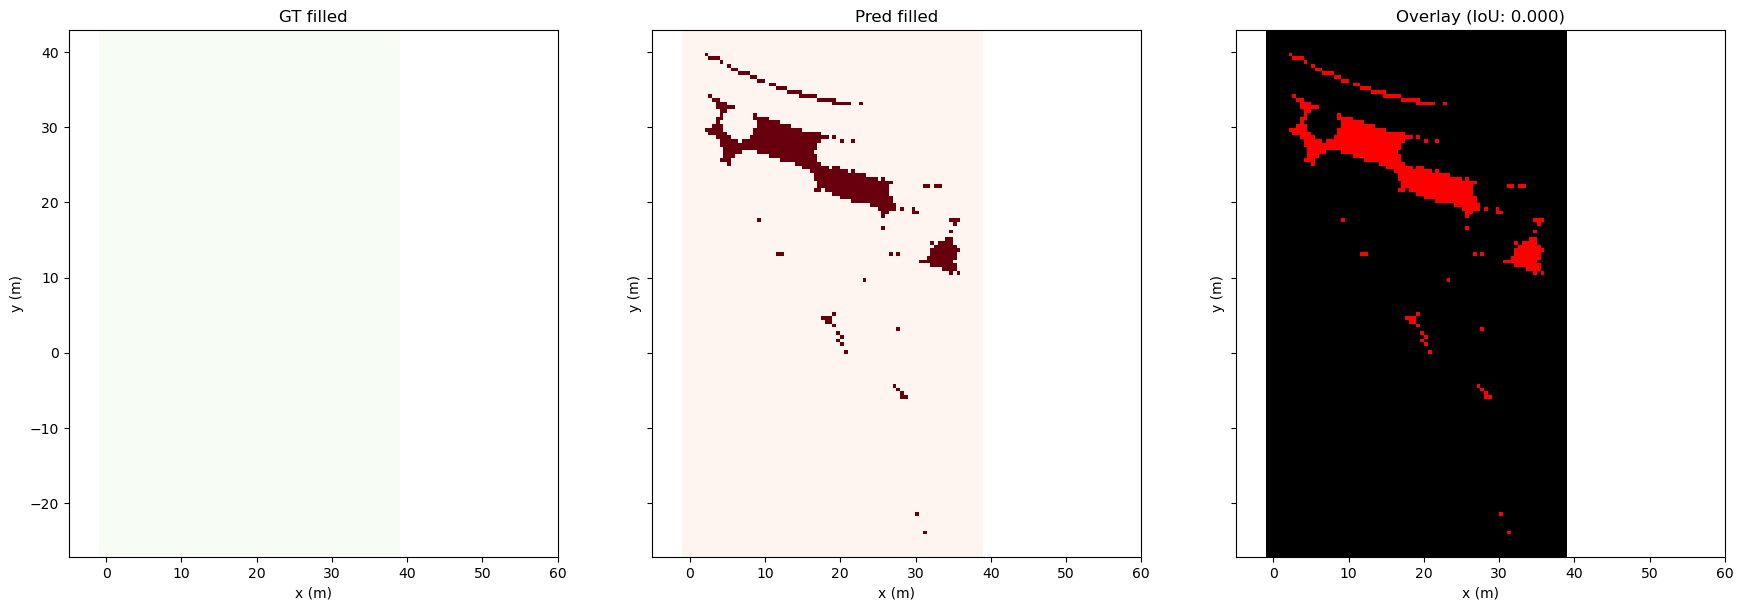

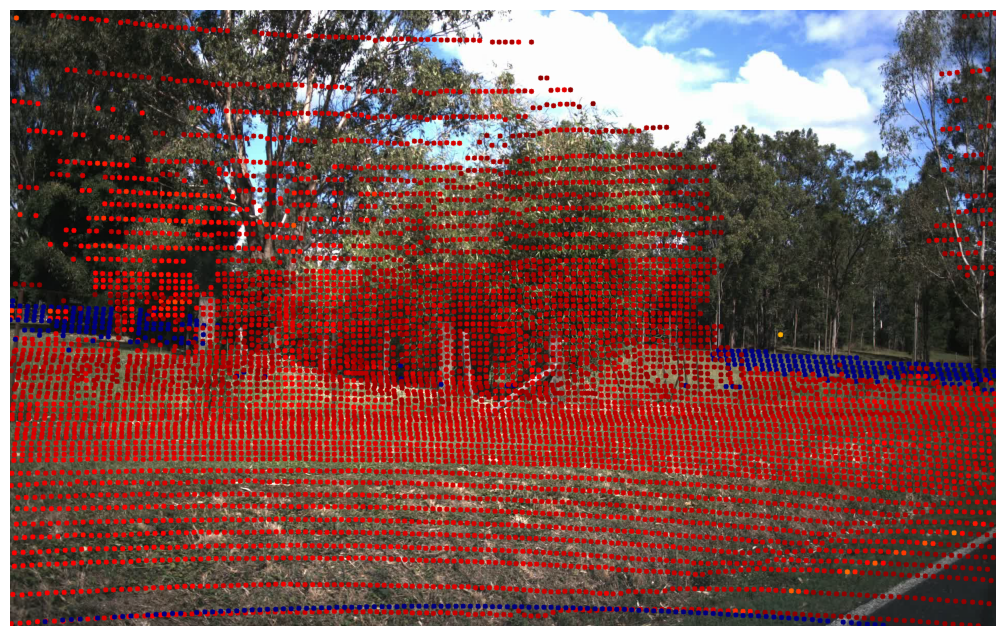

In [19]:
image_filename = f"{image_dir}/{image_timestamp}.png"
label_filename = f"{label_dir}/{image_timestamp}.png"
lidar_filename, lidar_semantic_filename, utm_filename = utils.get_corr_files(image_timestamp, [lidar_dir, lidar_gt_dir, utm_dir])

image = ImageData(image_filename, img_calib_file, label_filename)
pointcloud = PointCloud(lidar_filename, lidar_calib_file)
pointcloud_gt = np.fromfile(lidar_semantic_filename)

pointcloud.points, pointcloud.ground_semantic, pointcloud.ground_inlier = pointcloud.destagger() 

H, W = 64, 1024

# plt.figure()
# plt.imshow(pointcloud.points[:,3].reshape(64, 1024))
azimuth_angles = np.roll(2 * np.pi * (1.0 - np.arange(W) / W), 512) # centre is in the middle, maybe check direction?

# plt.figure()
# plt.plot(np.rad2deg(azimuth_angles))
beam_altitudes = np.deg2rad(np.array([
    20.97, 18.51, 15.97, 13.37, 12.04, 10.70, 9.35, 8.70,
    7.99, 7.34, 6.62, 5.96, 5.23, 4.55, 3.84, 3.51,
    3.17, 2.82, 2.46, 2.11, 1.76, 1.43, 1.05, 0.70,
    0.36, 0.03, -0.34, -0.70, -1.04, -1.37, -1.76, -2.10,
    -2.43, -2.77, -3.15, -3.48, -3.84, -4.18, -4.54, -4.88,
    -5.24, -5.55, -5.93, -6.29, -6.63, -6.94, -7.32, -7.67,
    -8.00, -8.33, -9.04, -9.71, -10.42, -11.06, -11.77, -12.41,
    -13.12, -13.74, -15.06, -16.36, -17.64, -18.91, -20.16, -21.38
]))

# a, b, c = utils.fit_height_field_linear(pointcloud.points[pointcloud.ground_semantic==0,:3])
a, b, c, d = np.loadtxt(f"{root_directory}/{location}_{sequence}/ouster_ground_equations/{lidar_filename.split('/')[-1].split('.bin')[0]}.txt")
# no_returns = np.sum(pointcloud.points, axis=1) == 0
no_returns = np.all(pointcloud.points[:, :4] == 0, axis=1)

# azimuth_array = np.tile(azimuth_angles, (H, 1)).reshape(H*W,)
# altitude_array = np.tile(beam_altitudes, (1, W)).reshape(H*W,)
azimuth_array  = np.tile(azimuth_angles, H)
altitude_array = np.repeat(beam_altitudes, W)

# def angle_to_ground_xyz(az, alt, a, b, c):
#     u = np.stack([np.cos(alt)*np.cos(az),
#                   np.cos(alt)*np.sin(az),
#                   np.sin(alt)], axis=-1)              # S + (3,)
#     denom = u[..., 2] - a*u[..., 0] - b*u[..., 1]     # S
#     with np.errstate(divide="ignore", invalid="ignore"):
#         t = c / denom                                  # S
#     xyz = t[..., None] * u                             # S + (3,)
#     xyz[~(np.isfinite(t) & (t > 0))] = np.nan
#     return xyz
def angle_to_ground_xyz(az, alt, a, b, c, d):
    """
    Ray from the sensor origin along (az, alt) intersected with the plane a*x + b*y + c*z + d = 0.
    az, alt: radians, same shape S. Returns S + (3,), NaN where there is no intersection.
    """
    u = np.stack([np.cos(alt) * np.cos(az),
                  np.cos(alt) * np.sin(az),
                  np.sin(alt)], axis=-1)              # S + (3,)
    denom = a * u[..., 0] + b * u[..., 1] + c * u[..., 2]     # n . u, shape S
    with np.errstate(divide="ignore", invalid="ignore"):
        t = -d / denom                                 # S
    xyz = t[..., None] * u                             # S + (3,)
    xyz[~(np.isfinite(t) & (t > 0))] = 0 #np.nan
    return xyz

# print(no_returns.shape)
# print(azimuth_array.shape)
# print(altitude_array.shape)

# labelled_points = np.hstack((pointcloud.points, np.zeros((pointcloud.points.shape[0], 1))))
labelled_points = np.concatenate([pointcloud.points, np.full((pointcloud.points.shape[0], 1), 0)], axis=-1)

ground_plane_points = angle_to_ground_xyz(azimuth_array[no_returns], altitude_array[no_returns], a, b, c, d)
ground_plane_points = np.concatenate([ground_plane_points, np.full((ground_plane_points.shape[0], 1), 255.0)], axis=-1)
pointcloud.points[no_returns] = ground_plane_points
ground_plane_points = np.concatenate([ground_plane_points, np.full((ground_plane_points.shape[0], 1), 1.0)], axis=-1)

# filter_mask = np.logical_or(np.logical_or(np.logical_or(np.linalg.norm(ground_plane_points[:,:3], axis=1) < 7, np.linalg.norm(ground_plane_points[:,:3], axis=1) > 40), (np.logical_or(ground_plane_points[:,1] < -5, ground_plane_points[:,1] > 2))), ground_plane_points[:,0] < 2) # np.logical_or(, ground_plane_points[:,0] > 40)
filter_mask = np.logical_or(np.logical_or(np.linalg.norm(ground_plane_points[:,:3], axis=1) < 7, np.linalg.norm(ground_plane_points[:,:3], axis=1) > 40), ground_plane_points[:,0] < 2)
ground_plane_points[filter_mask] = np.array([[0, 0, 0, 0, 0],])
labelled_points[no_returns] = ground_plane_points

for name, adx in [("gt", gt_points), ("pred", labelled_points)]:
    print(name, (~np.isfinite(np.asarray(adx)[:, :3])).any(1).sum(), "bad rows")

print(voxel_iou(gt_points, labelled_points, cls=1, voxel_size=3.0))

gt_water = gt_points[gt_points[:, 4] == 1]
pred_water = labelled_points[(labelled_points[:, 3] == 255) &
                             np.isfinite(labelled_points[:, :3]).all(1)]

res = raster_iou(gt_water, pred_water, cell=0.25)
print(res["iou"], res["precision"], res["recall"])

from scipy.ndimage import binary_closing

# cell = 0.5
# close_r = 2                    # m, ~half the radial ring spacing; report this
# gt_xy = gt_water[:, :2]
# pr_xy = pred_water[:, :2]

# pad = close_r + 1.0
# allxy = np.vstack([gt_xy, pr_xy])
# lo = allxy.min(0) - pad
# shape = np.ceil((allxy.max(0) + pad - lo) / cell).astype(int)

# def raster(xy):
#     g = np.zeros(shape, bool)
#     ij = np.floor((xy - lo) / cell).astype(int)
#     g[ij[:, 0], ij[:, 1]] = True
#     return g

# rc = int(round(close_r / cell))
# yy, xx = np.mgrid[-rc:rc + 1, -rc:rc + 1]
# disk = (xx**2 + yy**2) <= rc**2

# gt_fill = binary_closing(raster(gt_xy), structure=disk)
# pr_fill = binary_closing(raster(pr_xy), structure=disk)

# inter = (gt_fill & pr_fill).sum()
# union = (gt_fill | pr_fill).sum()
# print("IoU", inter / union, " prec", inter / pr_fill.sum(), " rec", inter / gt_fill.sum())

# # same, but only where the model could have predicted (GT inside the pred's extent)
# mask = binary_closing(raster(pr_xy), structure=np.ones((2*rc*2+1,)*2, bool))  # generous hull
# inter_m = (gt_fill & pr_fill & mask).sum()
# union_m = ((gt_fill & mask) | pr_fill).sum()
# print("IoU within pred extent", inter_m / union_m)

# extent = [lo[0], lo[0] + shape[0] * cell, lo[1], lo[1] + shape[1] * cell]

# fig, axs = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)

# axs[0].imshow(gt_fill.T, origin="lower", extent=extent, cmap="Greens")
# axs[0].set_title("GT filled")

# axs[1].imshow(pr_fill.T, origin="lower", extent=extent, cmap="Reds")
# axs[1].set_title("Pred filled")

# # overlay: green = GT only, red = pred only, yellow = both
# rgb = np.zeros((*gt_fill.T.shape, 3))
# rgb[..., 0] = pr_fill.T
# rgb[..., 1] = gt_fill.T
# axs[2].imshow(rgb, origin="lower", extent=extent)
# axs[2].set_title("Overlay (yellow = intersection)")

# for a in axs:
#     a.set_xlabel("x (m)")
#     a.set_ylabel("y (m)")
#     a.set_aspect("equal")
#     a.set_xlim(-5, 60)

# plt.tight_layout()
# plt.show()

# gt_water = gt_points[gt_points[:, 4] == 1]
# pred_water = labelled_points[(labelled_points[:, 3] == 255) &
#                             np.isfinite(labelled_points[:, :3]).all(1)]
cell = 0.5
close_r = 2                    # m, ~half the radial ring spacing; report this
gt_xy = gt_water[:, :2]
pr_xy = pred_water[:, :2]

pad = close_r + 1.0
allxy = np.vstack([gt_xy, pr_xy])
lo = allxy.min(0) - pad
shape = np.ceil((allxy.max(0) + pad - lo) / cell).astype(int)

rc = int(round(close_r / cell))
yy, xx = np.mgrid[-rc:rc + 1, -rc:rc + 1]
disk = (xx**2 + yy**2) <= rc**2

def raster(xy):
    g = np.zeros(shape, bool)
    ij = np.floor((xy - lo) / cell).astype(int)
    g[ij[:, 0], ij[:, 1]] = True
    return g

gt_fill = binary_closing(raster(gt_xy), structure=disk)
pr_fill = binary_closing(raster(pr_xy), structure=disk)


if has_gt:
    inter = (gt_fill & pr_fill).sum()
    union = (gt_fill | pr_fill).sum()

    iou = inter / union
    precision = inter / pr_fill.sum()
    recall = inter / gt_fill.sum()

    # same, but only where the model could have predicted (GT inside the pred's extent)
    mask = binary_closing(raster(pr_xy), structure=np.ones((2*rc*2+1,)*2, bool))  # generous hull
    inter_m = (gt_fill & pr_fill & mask).sum()
    union_m = ((gt_fill & mask) | pr_fill).sum()

    iou_m = inter_m / union_m
else:

    no_preds = np.all(np.all(labelled_points == 0, axis=1).astype(int))

    if no_preds:
        iou = precision = recall = iou_m = 1
    else:
        iou = precision = recall = iou_m = 0

print(f"IoU: {iou}")

extent = [lo[0], lo[0] + shape[0] * cell, lo[1], lo[1] + shape[1] * cell]

fig, axs = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)

axs[0].imshow(gt_fill.T, origin="lower", extent=extent, cmap="Greens")
axs[0].set_title("GT filled")

axs[1].imshow(pr_fill.T, origin="lower", extent=extent, cmap="Reds")
axs[1].set_title("Pred filled")

# overlay: green = GT only, red = pred only, yellow = both
rgb = np.zeros((*gt_fill.T.shape, 3))
rgb[..., 0] = pr_fill.T
rgb[..., 1] = gt_fill.T
axs[2].imshow(rgb, origin="lower", extent=extent)
axs[2].set_title(f"Overlay (IoU: {iou:.3f})")

for a in axs:
    a.set_xlabel("x (m)")
    a.set_ylabel("y (m)")
    a.set_aspect("equal")
    a.set_xlim(-5, 60)

plt.tight_layout()
plt.show()

# plt.figure()
# plt.imshow(pointcloud.points[:,3].reshape(H,W)[:,256:1024-256])
# plt.figure()
# plt.imshow(pointcloud.points[:,0].reshape(H,W)[:,256:1024-256])
# plt.figure()
# plt.imshow(pointcloud.points[:,1].reshape(H,W)[:,256:1024-256])
# plt.figure()
# plt.imshow(pointcloud.points[:,2].reshape(H,W)[:,256:1024-256])



# groundplane_eqn = utils.fit_height_field_linear(pointcloud.points[pointcloud.ground_semantic==0,:3])
# pointcloud.points, interp_flags = utils.complete_cloud(pointcloud.points, groundplane_eqn)
# pointcloud.points = pointcloud.points[interp_flags]

point_cam, distances_cam, intensities_cam, all_points_cam, valid_cam = pointcloud.points_ouster_to_cam()

img_vis, uv, valid_img, mask_img = image.project_points(
    all_points_cam,
    intensities_cam,
    cmap,
    valid_cam,
    colour_norm=255
)

# # # Work in image space from the start
# # pts = pointcloud.points.reshape(64, 1024, 4)
# # valid = valid_img.reshape(64, 1024)

# # # Non-return: every attribute (x, y, z, intensity) is exactly 0
# # no_return = (pts == 0).all(axis=-1)

# # intensity_img = np.where(valid, pts[..., 3], 0).astype(np.float32)
# # intensity_img[no_return] = 255  # sentinel for "no return"

# # # Crop using the valid-mask bounding box
# # rows = np.flatnonzero(valid.any(axis=1))
# # cols = np.flatnonzero(valid.any(axis=0))
# # intensity_img = intensity_img[
# #     rows[0]:rows[-1] + 1,
# #     cols[0]:cols[-1] + 1
# # ]


# # intensity_img = np.vstack((np.zeros((24, intensity_img.shape[1])), intensity_img, np.zeros((8, intensity_img.shape[1]))))

# # # ------------------------------------------------------------------
# # # Resize intensity image to the camera image dimensions
# # # ------------------------------------------------------------------
# # image_h, image_w = image.image.shape[:2]

# # intensity_img_resized = cv2.resize(
# #     intensity_img,
# #     (image_w, image_h),
# #     interpolation=cv2.INTER_NEAREST
# # )

# # # ------------------------------------------------------------------
# # # Display intensity image as an overlay on the camera image
# # # ------------------------------------------------------------------
# # fig, ax = plt.subplots(figsize=(12.8, 8))

# # ax.imshow(image.image[:,:,::-1])
# # ax.imshow(
# #     intensity_img_resized,
# #     cmap=cmap,
# #     alpha=0.5,
# #     vmin=0,
# #     vmax=255
# # )

# # ax.axis("off")
# # fig.canvas.draw()

# # mask_img = cv2.resize(
# #     mask_img,
# #     (image_w//5, image_h//5),
# #     interpolation=cv2.INTER_NEAREST
# # )

# # mask_img = cv2.resize(
# #     mask_img,
# #     (image_w, image_h),
# #     interpolation=cv2.INTER_NEAREST
# # )

# # fig, ax = plt.subplots(figsize=(12.8, 8))

# # ax.imshow(image.image[:,:,::-1])
# # ax.imshow(
# #     mask_img,
# #     cmap=cmap,
# #     alpha=0.5,
# #     vmin=0,
# #     vmax=255
# # )

# # ax.axis("off")
# # fig.canvas.draw()

fig, ax = plt.subplots(figsize=(12.8, 8))

ax.imshow(img_vis[:,:,::-1])

ax.axis("off")
fig.canvas.draw()

# pts_all = labelled_points
# finite = np.isfinite(pts_all[:, :3]).all(axis=1)
# nonzero = ~np.all(pts_all[:, :3] == 0, axis=1)

# rng = np.full(len(pts_all), np.inf)
# rng[finite] = np.linalg.norm(pts_all[finite, :3], axis=1)     # avoids NaN warnings

# keep = finite & nonzero & (rng <= 100.0)
# pts_vis = pts_all[keep]

# xyz = pts_vis[:, :3]
# inten = pts_vis[:, 3]

# # colour: grey by intensity, synthetic non-return points (255) in red
# grey = np.clip(inten / 255.0, 0, 1)
# colors = np.stack([grey, grey, grey], axis=1)
# colors[inten == 255] = [1.0, 0.0, 0.0]

# pcd = o3d.geometry.PointCloud()
# pcd.points = o3d.utility.Vector3dVector(xyz)
# pcd.colors = o3d.utility.Vector3dVector(colors)

# # ground truth: class 1 only, in green
# gt_cls = gt_points[gt_points[:, 4] == 1]
# gt_finite = np.isfinite(gt_cls[:, :3]).all(axis=1)
# gt_xyz = gt_cls[gt_finite, :3]

# pcd_gt = o3d.geometry.PointCloud()
# pcd_gt.points = o3d.utility.Vector3dVector(gt_xyz)
# pcd_gt.paint_uniform_color([0.0, 0.8, 0.0])

# axes = o3d.geometry.TriangleMesh.create_coordinate_frame(size=2.0)   # sensor origin
# o3d.visualization.draw_geometries([pcd, pcd_gt, axes])

In [20]:
# image_timestamp = timestamps[idx]

# image_filename = f"{image_dir}/{image_timestamp}.png"
# label_filename = f"{label_dir}/{image_timestamp}.png"
# lidar_filename, utm_filename = utils.get_corr_files(image_timestamp, [lidar_dir, utm_dir])

# image = ImageData(image_filename, img_calib_file, label_filename)
# pointcloud = PointCloud(lidar_filename, lidar_calib_file)

# pointcloud.points, pointcloud.ground_semantic, pointcloud.ground_inlier = pointcloud.destagger() #pointcloud.points, pointcloud.ground_semantic, pointcloud.ground_inlier
# # groundplane_eqn = utils.fit_height_field_linear(pointcloud.points[pointcloud.ground_semantic==0,:3])
# # pointcloud.points, interp_flags = utils.complete_cloud(pointcloud.points, groundplane_eqn)

# # pointcloud.points = pointcloud.points[interp_flags]

# point_cam, distances_cam, intensities_cam, all_points_cam, valid_cam = pointcloud.points_ouster_to_cam() #, beam_id, azimuth
# img_vis, uv, valid_img, _ = image.project_points(all_points_cam, intensities_cam, cmap, valid_cam, colour_norm=255) #, beam_id, azimuth

# # ------------------------------------------------------------
# # Projected LiDAR intensity -> dense camera image
# # ------------------------------------------------------------
# image_h, image_w = image.image.shape[:2]

# valid = valid_img.copy()

# uv_valid = uv[valid]
# intensity_valid = intensities_cam[valid].astype(np.float32)

# # Integer pixel coordinates
# u = np.round(uv_valid[:, 0]).astype(np.int32)
# v = np.round(uv_valid[:, 1]).astype(np.int32)

# # Make absolutely sure everything is inside the image
# inside = (
#     (u >= 0) & (u < image_w) &
#     (v >= 0) & (v < image_h)
# )

# u = u[inside]
# v = v[inside]
# intensity_valid = intensity_valid[inside]

# # ------------------------------------------------------------
# # Sparse projected image
# # ------------------------------------------------------------
# intensity_sparse = np.zeros(
#     (image_h, image_w),
#     dtype=np.float32
# )

# intensity_sparse[v, u] = intensity_valid

# # ------------------------------------------------------------
# # Build a dense representation
# # ------------------------------------------------------------

# # Start with nearest-neighbour expansion.
# # This makes each LiDAR measurement cover a larger region.
# kernel_size = 31

# kernel = cv2.getStructuringElement(
#     cv2.MORPH_ELLIPSE,
#     (kernel_size, kernel_size)
# )

# # Propagate the nearest intensity value
# intensity_dense = cv2.dilate(
#     intensity_sparse,
#     kernel
# )

# # Corresponding support mask
# support = np.zeros(
#     (image_h, image_w),
#     dtype=np.uint8
# )

# support[v, u] = 255

# support_dense = cv2.dilate(
#     support,
#     kernel
# )

# # ------------------------------------------------------------
# # Fill gaps with a smoother interpolation
# # ------------------------------------------------------------

# # Gaussian smoothing gives a continuous-looking result
# intensity_smooth = cv2.GaussianBlur(
#     intensity_dense,
#     (31, 31),
#     0
# )

# # ------------------------------------------------------------
# # Overlay
# # ------------------------------------------------------------

# fig, ax = plt.subplots(figsize=(12.8, 8))

# ax.imshow(image.image[:,:,::-1])

# intensity_display = np.ma.masked_where(
#     support_dense == 0,
#     intensity_smooth
# )

# ax.imshow(
#     intensity_display,
#     cmap=cmap,
#     alpha=0.65,
#     vmin=0,
#     vmax=255
# )

# ax.axis("off")
# fig.canvas.draw()

In [21]:
# image_timestamp = timestamps[idx]

# image_filename = f"{image_dir}/{image_timestamp}.png"
# label_filename = f"{label_dir}/{image_timestamp}.png"
# lidar_filename, utm_filename = utils.get_corr_files(image_timestamp, [lidar_dir, utm_dir])

# image = ImageData(image_filename, img_calib_file, label_filename)
# pointcloud = PointCloud(lidar_filename, lidar_calib_file)

# pointcloud.points, pointcloud.ground_semantic, pointcloud.ground_inlier = pointcloud.destagger() #pointcloud.points, pointcloud.ground_semantic, pointcloud.ground_inlier
# # groundplane_eqn = utils.fit_height_field_linear(pointcloud.points[pointcloud.ground_semantic==0,:3])
# # pointcloud.points, interp_flags = utils.complete_cloud(pointcloud.points, groundplane_eqn)

# # pointcloud.points = pointcloud.points[interp_flags]

# point_cam, distances_cam, intensities_cam, all_points_cam, valid_cam = pointcloud.points_ouster_to_cam() #, beam_id, azimuth


# # ------------------------------------------------------------
# # Original LiDAR image
# # ------------------------------------------------------------
# pts = pointcloud.points.reshape(64, 1024, 4)

# # Exactly your original no-return definition
# no_return = (pts == 0).all(axis=-1)

# # Original intensity values
# lidar_intensity = pts[..., 3].astype(np.float32)

# # ------------------------------------------------------------
# # Projected camera coordinates
# # ------------------------------------------------------------
# img_vis, uv, valid_img, _ = image.project_points(
#     all_points_cam,
#     intensities_cam,
#     cmap,
#     valid_cam,
#     colour_norm=255
# )

# image_h, image_w = image.image.shape[:2]

# # valid_img corresponds to the flattened point cloud
# valid = valid_img.reshape(-1)

# uv_all = uv.reshape(-1, 2)
# intensity_all = lidar_intensity.reshape(-1)
# no_return_all = no_return.reshape(-1)

# # Valid projected points
# u = np.round(uv_all[valid, 0]).astype(np.int32)
# v = np.round(uv_all[valid, 1]).astype(np.int32)

# intensity = intensity_all[valid].copy()
# no_return_projected = no_return_all[valid]

# # ------------------------------------------------------------
# # Keep points inside image
# # ------------------------------------------------------------
# inside = (
#     (u >= 0) & (u < image_w) &
#     (v >= 0) & (v < image_h)
# )

# u = u[inside]
# v = v[inside]
# intensity = intensity[inside]
# no_return_projected = no_return_projected[inside]

# # Explicit no-return value
# intensity[no_return_projected] = 255

# # ------------------------------------------------------------
# # Sparse camera-resolution intensity image
# # ------------------------------------------------------------
# intensity_sparse = np.zeros(
#     (image_h, image_w),
#     dtype=np.float32
# )

# # If multiple LiDAR samples hit the same camera pixel,
# # retain the maximum intensity.
# np.maximum.at(
#     intensity_sparse,
#     (v, u),
#     intensity
# )

# # Actual projected support
# support = np.zeros(
#     (image_h, image_w),
#     dtype=np.uint8
# )

# support[v, u] = 255

# # ------------------------------------------------------------
# # Make dense
# # ------------------------------------------------------------
# # This expands the projected LiDAR samples into a dense image.
# # Increase this for more filling.
# kernel_size = 31

# kernel = cv2.getStructuringElement(
#     cv2.MORPH_ELLIPSE,
#     (kernel_size, kernel_size)
# )

# intensity_dense = cv2.dilate(
#     intensity_sparse,
#     kernel
# )

# support_dense = cv2.dilate(
#     support,
#     kernel
# )

# # ------------------------------------------------------------
# # Overlay
# # ------------------------------------------------------------
# fig, ax = plt.subplots(figsize=(12.8, 8))

# ax.imshow(image.image)

# intensity_display = np.ma.masked_where(
#     support_dense == 0,
#     intensity_dense
# )

# ax.imshow(
#     intensity_display,
#     cmap=cmap,
#     alpha=0.6,
#     vmin=0,
#     vmax=255
# )

# ax.axis("off")
# fig.canvas.draw()